In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

In [3]:
# Load cleaned dataset (keep_default_na=False prevents pandas from turning 'None' into NaN)
df = pd.read_csv("hotels_model_ready.csv", keep_default_na=False)

# Enforce exact data types
df["arrival_date"] = pd.to_datetime(df["arrival_date"])
df["children"] = df["children"].astype(float).astype(int)
df["total_guests"] = df["total_guests"].astype(float).astype(int)
df["agent"] = df["agent"].astype(str)
df["company"] = df["company"].astype(str)

print(f"Loaded Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date Range: {df['arrival_date'].min().date()} to {df['arrival_date'].max().date()}")
print(f"Missing Values: {df.isnull().sum().sum()}")
df.head(3)

Loaded Shape: 119,390 rows x 28 columns
Date Range: 2015-07-01 to 2017-08-31
Missing Values: 0


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,company,customer_type,adr,nights,total_guests,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0,C,No Deposit,None,None,Transient,0.0,0,2,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0,C,No Deposit,None,None,Transient,0.0,0,2,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,A,No Deposit,None,None,Transient,75.0,1,1,2015-07-01


In [4]:
# Exact scoring constants and functions from src/contract.py
WALK_COST = 300.0          # EUR per walked guest
WALK_CEILING = 10.0        # Max walked guests per 1,000 arrivals
TRAIN_END = "2016-07-01"
PROOF_START = "2017-01-01"
REQUIRED = ["hotel", "arrival_date", "is_canceled", "adr", "nights"]

def split_periods(df):
    train = df[df["arrival_date"] < TRAIN_END].copy()
    choose = df[(df["arrival_date"] >= TRAIN_END) & (df["arrival_date"] < PROOF_START)].copy()
    proof = df[df["arrival_date"] >= PROOF_START].copy()
    return train, choose, proof

def nightly_table(bookings, prob):
    p = np.asarray(prob, dtype=float)
    f = bookings.assign(_p=p, _var=p * (1 - p), _value=bookings["adr"] * bookings["nights"])
    return f.groupby(["hotel", "arrival_date"]).agg(
        book=("is_canceled", "size"),
        cancelled=("is_canceled", "sum"),
        expected=("_p", "sum"),
        spread=("_var", lambda v: float(np.sqrt(v.sum()))),
        stay_value=("_value", "mean"),
    )

def night_cost(nights, oversell):
    k = pd.Series(np.asarray(oversell, dtype=float), index=nights.index)
    empty = (nights["cancelled"] - k).clip(lower=0)
    walks = (k - nights["cancelled"]).clip(lower=0)
    arrivals = (nights["book"] - nights["cancelled"]).sum()
    walk_rate = 1000.0 * walks.sum() / arrivals if arrivals else float("nan")
    cost = float((empty * nights["stay_value"]).sum() + (walks * WALK_COST).sum())
    return {
        "cost_eur": round(cost, 2),
        "empty_rooms": int(empty.sum()),
        "walked_guests": int(walks.sum()),
        "walks_per_1000": round(float(walk_rate), 2),
        "ceiling_met": bool(walk_rate <= WALK_CEILING),
        "nights": int(len(nights)),
    }

train, choose, proof = split_periods(df)
print(f"Train (< 2016-07-01):  {len(train):,} bookings")
print(f"Choose (2016 H2):      {len(choose):,} bookings")
print(f"Proof (2017 Jan-Aug):  {len(proof):,} bookings")

Train (< 2016-07-01):  49,157 bookings
Choose (2016 H2):      29,546 bookings
Proof (2017 Jan-Aug):  40,687 bookings


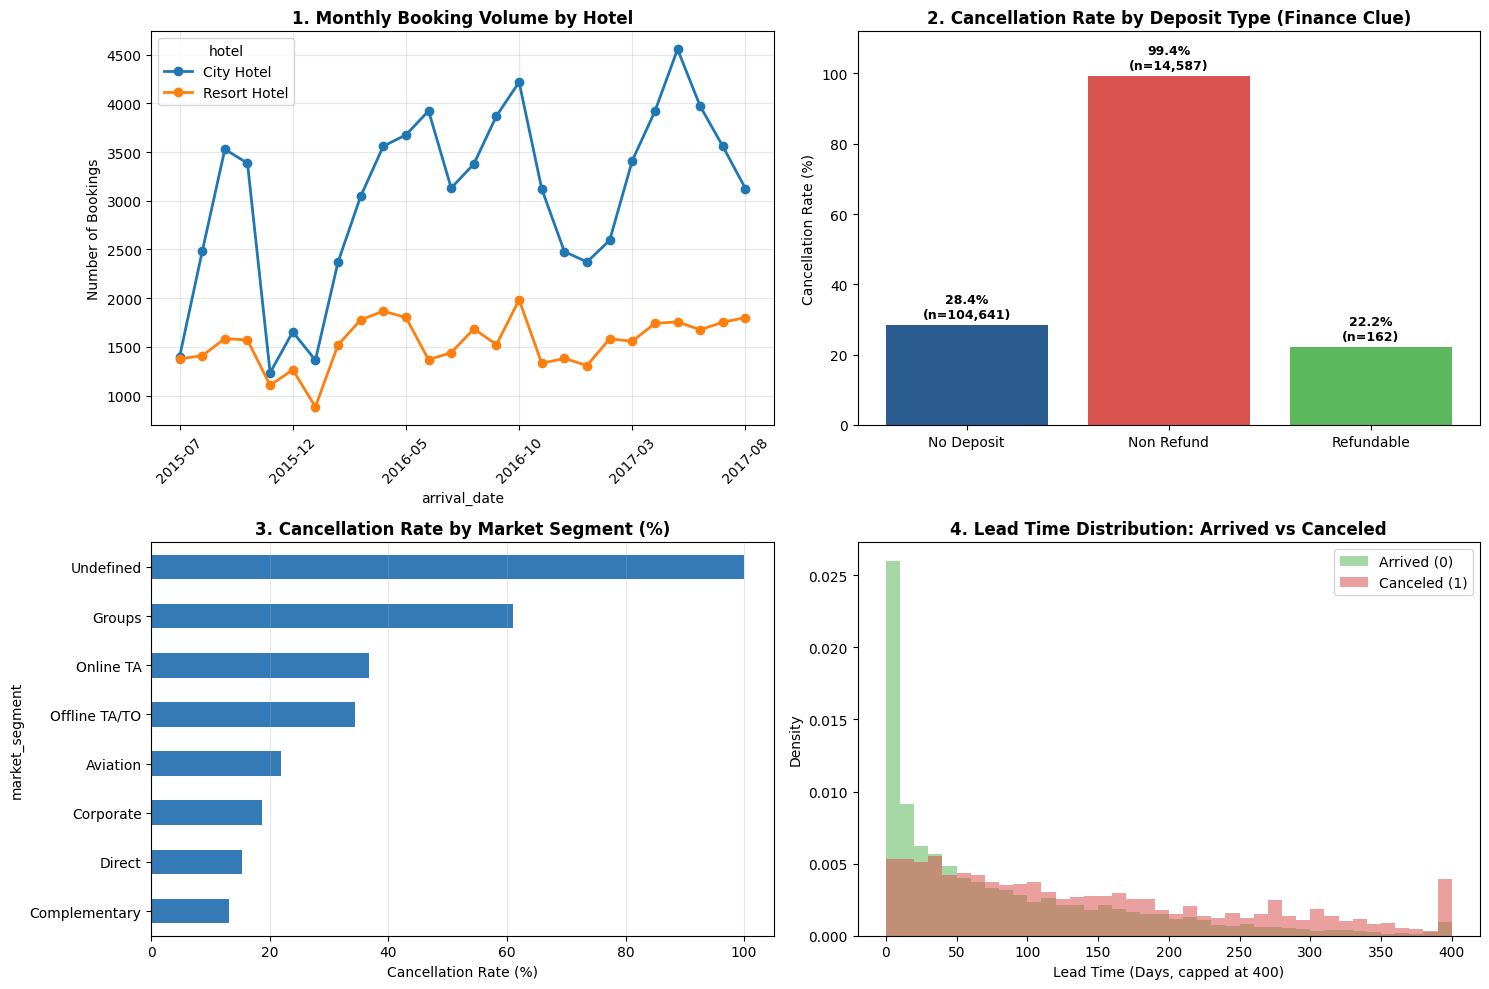

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Monthly Booking Demand by Hotel
monthly_vol = df.groupby([df["arrival_date"].dt.to_period("M"), "hotel"]).size().unstack()
monthly_vol.index = monthly_vol.index.astype(str)
monthly_vol.plot(ax=axes[0, 0], marker="o", linewidth=2)
axes[0, 0].set_title("1. Monthly Booking Volume by Hotel", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Number of Bookings")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(alpha=0.3)

# Plot 2: Cancellation Rate by Deposit Type (Proving Finance's Clue #1)
dep = df.groupby("deposit_type")["is_canceled"].agg(["count", "mean"])
bars = axes[0, 1].bar(dep.index, dep["mean"] * 100, color=["#2b5c8f", "#d9534f", "#5cb85c"])
axes[0, 1].set_title("2. Cancellation Rate by Deposit Type (Finance Clue)", fontsize=12, fontweight="bold")
axes[0, 1].set_ylabel("Cancellation Rate (%)")
axes[0, 1].set_ylim(0, 112)
for bar, (_, row) in zip(bars, dep.iterrows()):
    axes[0, 1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{row['mean']*100:.1f}%\n(n={int(row['count']):,})",
        ha="center",
        fontweight="bold",
        fontsize=9,
    )

# Plot 3: Cancellation Rate by Market Segment
seg = df.groupby("market_segment")["is_canceled"].mean().sort_values() * 100
seg.plot(kind="barh", ax=axes[1, 0], color="#337ab7")
axes[1, 0].set_title("3. Cancellation Rate by Market Segment (%)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Cancellation Rate (%)")
axes[1, 0].grid(axis="x", alpha=0.3)

# Plot 4: Lead Time Distribution (Canceled vs Arrived)
for status, label, color in [(0, "Arrived (0)", "#5cb85c"), (1, "Canceled (1)", "#d9534f")]:
    subset = df[df["is_canceled"] == status]["lead_time"].clip(upper=400)
    axes[1, 1].hist(subset, bins=40, alpha=0.55, density=True, label=label, color=color)
axes[1, 1].set_title("4. Lead Time Distribution: Arrived vs Canceled", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Lead Time (Days, capped at 400)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [6]:
NUMERIC_FEATURES = [
    "lead_time", "arrival_date_year", "arrival_date_day_of_month", "arrival_date_week_number",
    "stays_in_weekend_nights", "stays_in_week_nights", "nights", "adults", "children",
    "babies", "total_guests", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "adr",
]

CATEGORICAL_FEATURES = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type",
    "agent", "company", "customer_type",
]

FEATURE_COLS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Ensure no target or contract date leakage is inside FEATURE_COLS
assert "is_canceled" not in FEATURE_COLS
assert "arrival_date" not in FEATURE_COLS

prep_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL_FEATURES),
])

prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
])

print(f"Total Bin-1 Features Ready: {len(FEATURE_COLS)} ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)")

Total Bin-1 Features Ready: 26 (15 numeric, 11 categorical)


In [7]:
models = {
    "Decision Tree (Depth 8)": Pipeline([("prep", prep_tree), ("clf", DecisionTreeClassifier(max_depth=8, random_state=42))]),
    "Logistic Regression": Pipeline([("prep", prep_linear), ("clf", LogisticRegression(max_iter=500))]),
    "Random Forest": Pipeline([("prep", prep_tree), ("clf", RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))]),
    "Gradient Boosted Trees (GBDT)": Pipeline([("prep", prep_tree), ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42))]),
}

def compute_oversell(nights_df, z_buffer):
    raw_k = nights_df["expected"] - z_buffer * nights_df["spread"]
    return np.maximum(0, np.round(raw_k)).astype(int)

def tune_buffer(nights_df):
    best_z, best_score = 3.0, None
    for z in np.linspace(0.0, 3.0, 301):
        sc = night_cost(nights_df, compute_oversell(nights_df, z))
        if sc["ceiling_met"] and (best_score is None or sc["cost_eur"] < best_score["cost_eur"]):
            best_z, best_score = round(float(z), 4), sc
    if best_score is None:
        best_score = night_cost(nights_df, compute_oversell(nights_df, 3.0))
    return best_z, best_score

X_train, y_train = train[FEATURE_COLS], train["is_canceled"]
X_choose, y_choose = choose[FEATURE_COLS], choose["is_canceled"]
X_proof, y_proof = proof[FEATURE_COLS], proof["is_canceled"]

# 1. Baselines: Zero Oversell & Client's Flat Rule
hotel_rates = train.groupby("hotel")["is_canceled"].mean().to_dict()
n_ch_flat = nightly_table(choose, choose["hotel"].map(hotel_rates).values)
z_flat, _ = tune_buffer(n_ch_flat)

n_pr_zero = nightly_table(proof, np.zeros(len(proof)))
res_zero = night_cost(n_pr_zero, np.zeros(len(n_pr_zero)))

n_pr_flat = nightly_table(proof, proof["hotel"].map(hotel_rates).values)
res_flat = night_cost(n_pr_flat, compute_oversell(n_pr_flat, z_flat))

results = [
    {"Policy": "Baseline 1: Zero Oversell (k=0)", "Choose AUC": "-", "Proof AUC": "-", "Brier": "-", "Buffer (z)": "-", **res_zero},
    {"Policy": "Baseline 2: Client Flat Rule", "Choose AUC": "-", "Proof AUC": "-", "Brier": "-", "Buffer (z)": z_flat, **res_flat},
]

proof_predictions = {}
fitted_models = {}
tuned_buffers = {}

# 2. Fit & Evaluate All 4 Supervised Models
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p_ch = pipe.predict_proba(X_choose)[:, 1]
    p_pr = pipe.predict_proba(X_proof)[:, 1]

    n_ch = nightly_table(choose, p_ch)
    z_opt, _ = tune_buffer(n_ch)

    n_pr = nightly_table(proof, p_pr)
    res_pr = night_cost(n_pr, compute_oversell(n_pr, z_opt))

    proof_predictions[name] = p_pr
    fitted_models[name] = pipe
    tuned_buffers[name] = z_opt

    results.append({
        "Policy": name,
        "Choose AUC": round(roc_auc_score(y_choose, p_ch), 4),
        "Proof AUC": round(roc_auc_score(y_proof, p_pr), 4),
        "Brier": round(brier_score_loss(y_proof, p_pr), 4),
        "Buffer (z)": z_opt,
        **res_pr,
    })

summary_df = pd.DataFrame(results)
display(summary_df)

,Policy,Choose AUC,Proof AUC,Brier,Buffer (z),cost_eur,empty_rooms,walked_guests,walks_per_1000,ceiling_met,nights
0,Baseline 1: Zero Oversell (k=0),-,-,-,-,6714098.55,15745,0,0.00,True,486
1,Baseline 2: Client Flat Rule,-,-,-,3.0,3423182.40,7188,185,7.42,True,486
2,Decision Tree (Depth 8),0.8045,0.7913,0.174,0.67,1951002.83,3746,187,7.50,True,486
3,Logistic Regression,0.8175,0.8226,0.1797,0.0,2291077.30,4560,138,5.53,True,486
4,Random Forest,0.8231,0.8223,0.1669,0.0,1665079.59,3198,205,8.22,True,486
5,Gradient Boosted Trees (GBDT),0.8344,0.8346,0.1622,0.0,1625177.30,3023,194,7.78,True,486


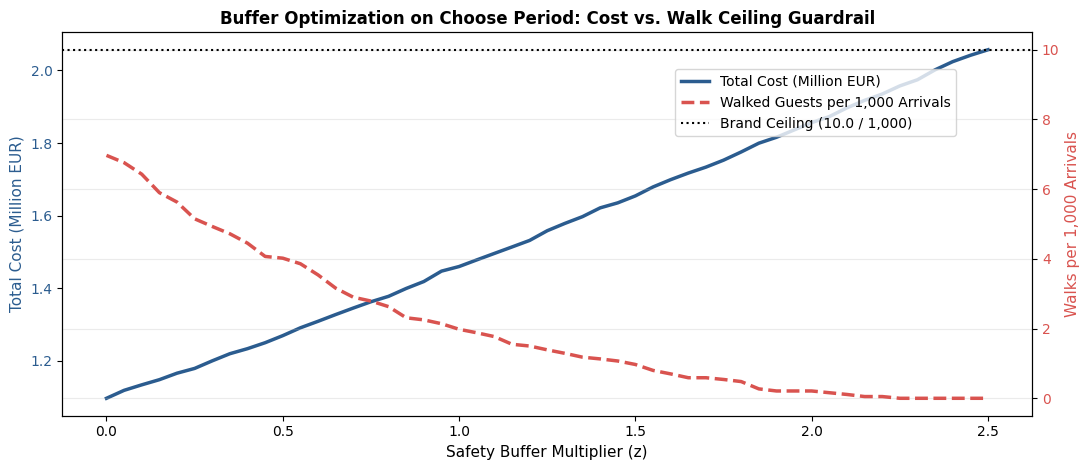

In [8]:
# Show how tuning 'z' on the Choose period balances Empty Room Cost vs Walked Guest Guardrail
p_ch_gbdt = fitted_models["Gradient Boosted Trees (GBDT)"].predict_proba(X_choose)[:, 1]
n_ch_gbdt = nightly_table(choose, p_ch_gbdt)

z_grid = np.linspace(0.0, 2.5, 51)
costs, walk_rates = [], []
for z in z_grid:
    sc = night_cost(n_ch_gbdt, compute_oversell(n_ch_gbdt, z))
    costs.append(sc["cost_eur"] / 1e6)
    walk_rates.append(sc["walks_per_1000"])

fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.plot(z_grid, costs, color="#2b5c8f", linewidth=2.5, label="Total Cost (Million EUR)")
ax1.set_xlabel("Safety Buffer Multiplier (z)", fontsize=11)
ax1.set_ylabel("Total Cost (Million EUR)", color="#2b5c8f", fontsize=11)
ax1.tick_params(axis="y", labelcolor="#2b5c8f")

ax2 = ax1.twinx()
ax2.plot(z_grid, walk_rates, color="#d9534f", linewidth=2.5, linestyle="--", label="Walked Guests per 1,000 Arrivals")
ax2.axhline(10.0, color="black", linestyle=":", linewidth=1.5, label="Brand Ceiling (10.0 / 1,000)")
ax2.set_ylabel("Walks per 1,000 Arrivals", color="#d9534f", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#d9534f")

plt.title("Buffer Optimization on Choose Period: Cost vs. Walk Ceiling Guardrail", fontsize=12, fontweight="bold")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.86))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

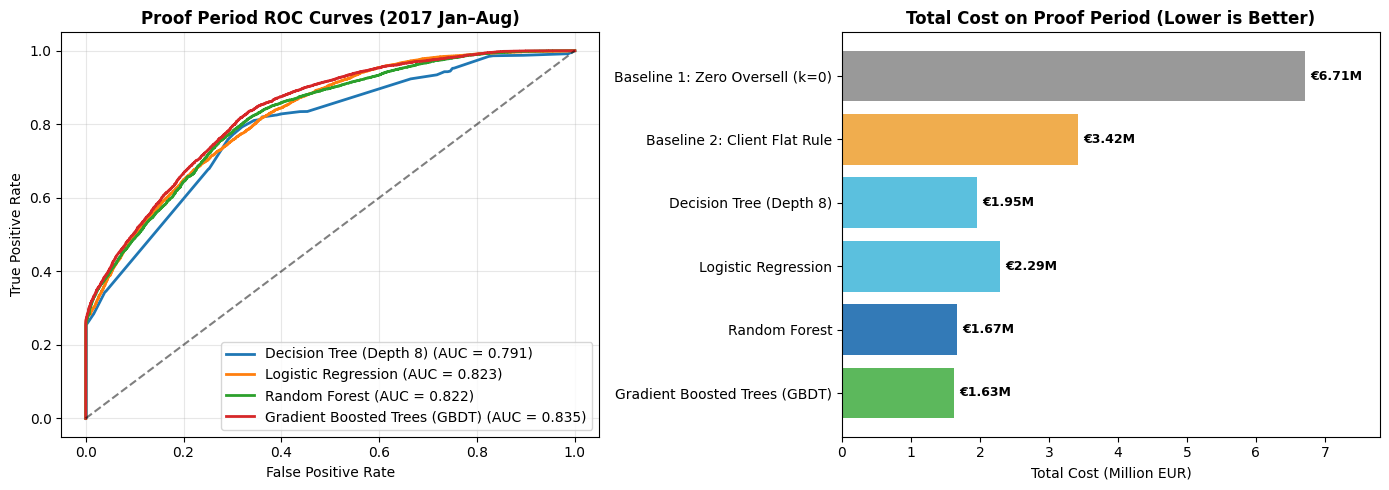

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ROC Curves on Proof Period
for name, p_pr in proof_predictions.items():
    fpr, tpr, _ = roc_curve(y_proof, p_pr)
    auc_score = roc_auc_score(y_proof, p_pr)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_score:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Proof Period ROC Curves (2017 Jan–Aug)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Right: Total Financial Cost Comparison (EUR)
colors = ["#999999", "#f0ad4e", "#5bc0de", "#5bc0de", "#337ab7", "#5cb85c"]
bars = axes[1].barh(summary_df["Policy"], summary_df["cost_eur"] / 1e6, color=colors)
axes[1].set_title("Total Cost on Proof Period (Lower is Better)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Total Cost (Million EUR)")
axes[1].invert_yaxis()
for bar in bars:
    axes[1].text(bar.get_width() + 0.08, bar.get_y() + bar.get_height() / 2, f"€{bar.get_width():.2f}M", va="center", fontsize=9, fontweight="bold")
axes[1].set_xlim(0, 7.8)

plt.tight_layout()
plt.show()

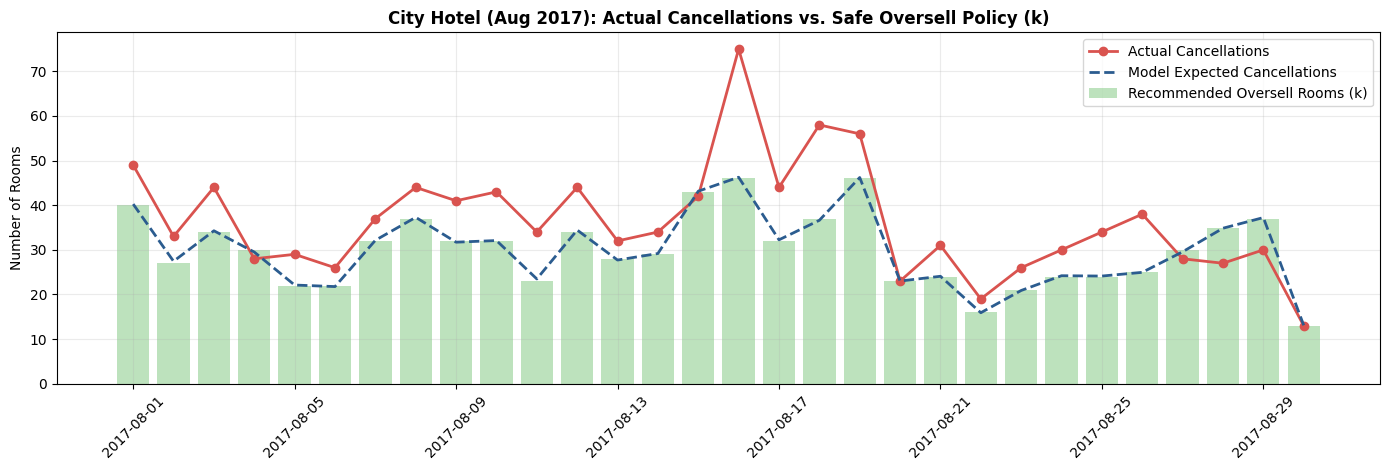

In [10]:
best_model_name = "Gradient Boosted Trees (GBDT)"
best_p_proof = proof_predictions[best_model_name]
best_z = tuned_buffers[best_model_name]

nights_proof = nightly_table(proof, best_p_proof)
nights_proof["oversell_k"] = compute_oversell(nights_proof, best_z)

# Plot first 30 nights of August 2017 for City Hotel
aug_city = nights_proof.loc["City Hotel"].loc["2017-08-01":"2017-08-30"]

plt.figure(figsize=(14, 4.8))
plt.plot(aug_city.index, aug_city["cancelled"], marker="o", color="#d9534f", linewidth=2, label="Actual Cancellations")
plt.plot(aug_city.index, aug_city["expected"], linestyle="--", color="#2b5c8f", linewidth=2, label="Model Expected Cancellations")
plt.bar(aug_city.index, aug_city["oversell_k"], color="#5cb85c", alpha=0.4, label="Recommended Oversell Rooms (k)")
plt.title("City Hotel (Aug 2017): Actual Cancellations vs. Safe Oversell Policy (k)", fontsize=12, fontweight="bold")
plt.ylabel("Number of Rooms")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

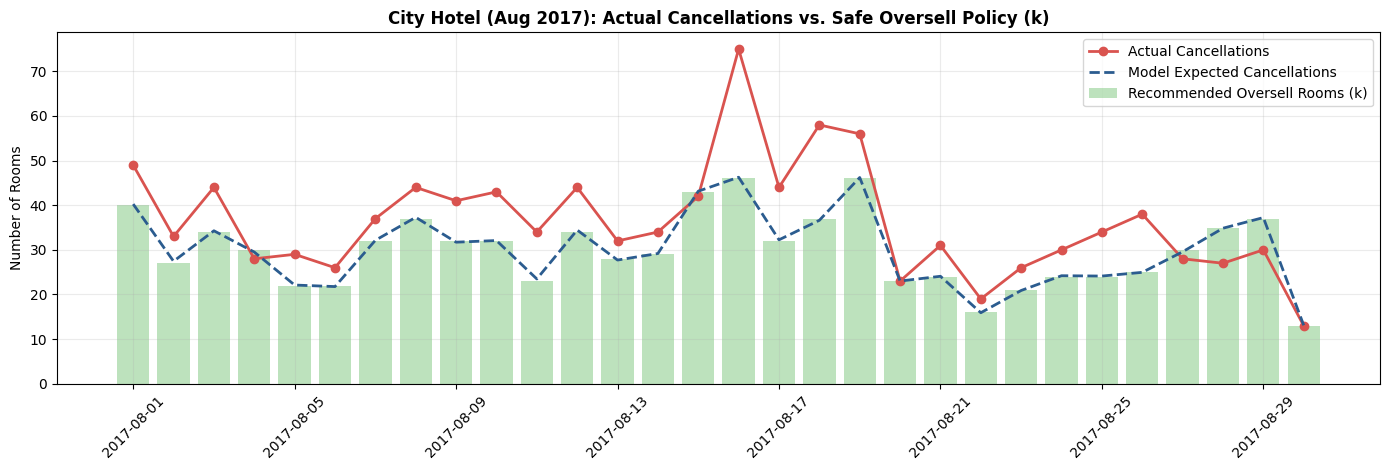

In [11]:
best_model_name = "Gradient Boosted Trees (GBDT)"
best_p_proof = proof_predictions[best_model_name]
best_z = tuned_buffers[best_model_name]

nights_proof = nightly_table(proof, best_p_proof)
nights_proof["oversell_k"] = compute_oversell(nights_proof, best_z)

# Plot first 30 nights of August 2017 for City Hotel
aug_city = nights_proof.loc["City Hotel"].loc["2017-08-01":"2017-08-30"]

plt.figure(figsize=(14, 4.8))
plt.plot(aug_city.index, aug_city["cancelled"], marker="o", color="#d9534f", linewidth=2, label="Actual Cancellations")
plt.plot(aug_city.index, aug_city["expected"], linestyle="--", color="#2b5c8f", linewidth=2, label="Model Expected Cancellations")
plt.bar(aug_city.index, aug_city["oversell_k"], color="#5cb85c", alpha=0.4, label="Recommended Oversell Rooms (k)")
plt.title("City Hotel (Aug 2017): Actual Cancellations vs. Safe Oversell Policy (k)", fontsize=12, fontweight="bold")
plt.ylabel("Number of Rooms")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [12]:
# Matches Slide 7 live CLI deliverable: 14 nights starting 2017-08-18
schedule = nights_proof.reset_index()
mask = (schedule["arrival_date"] >= "2017-08-18") & (schedule["arrival_date"] < "2017-09-01")
fourteen_day_table = schedule[mask][["hotel", "arrival_date", "book", "expected", "spread", "oversell_k"]].copy()
fourteen_day_table["expected"] = fourteen_day_table["expected"].round(1)
fourteen_day_table["spread"] = fourteen_day_table["spread"].round(2)

print("=== 14-NIGHT OVERSELL SCHEDULE (2017-08-18 to 2017-08-31) ===")
display(fourteen_day_table)

=== 14-NIGHT OVERSELL SCHEDULE (2017-08-18 to 2017-08-31) ===


,hotel,arrival_date,book,expected,spread,oversell_k
229,City Hotel,2017-08-18,121,36.6,4.74,37
230,City Hotel,2017-08-19,122,46.2,4.25,46
231,City Hotel,2017-08-20,101,23.0,3.84,23
232,City Hotel,2017-08-21,94,24.1,3.89,24
233,City Hotel,2017-08-22,60,15.9,3.17,16
234,City Hotel,2017-08-23,86,20.9,3.60,21
235,City Hotel,2017-08-24,91,24.2,3.91,24
236,City Hotel,2017-08-25,139,24.1,3.75,24
237,City Hotel,2017-08-26,101,25.0,3.86,25
238,City Hotel,2017-08-27,107,29.6,4.25,30
